# Gradient Boosting

This notebook introduces gradient boosted regression trees, compares them with random forests, and examines how tree depth and learning rate control model complexity on the breast cancer data.

## 1. Core idea

Gradient boosting builds an additive model in a stage-wise manner: each new tree is trained to correct the errors (residuals) of the current ensemble. It performs gradient descent in function space.

\begin{align*}
F_M(x) = \sum_{m=1}^{M}\gamma_m h_m(x)
\end{align*}

where
- $h_m(x)$ = weak learner (usually a shallow tree)
- $\gamma_m$ = step size
- $M$ = number of boosting iterations

## 2. Intuition

Instead of reducing variance by averaging many trees (random forest), boosting reduces bias by improving the model sequentially. Each new tree focuses on
- where the model performs poorly
- the direction of steepest loss reduction

## 3. Key hyperparameters

- `n_estimators`: number of trees ($M$)
- `learning_rate`: step size
- `max_depth`: tree depth (controls complexity)
- `subsample`: stochastic boosting (optional)

Important trade-off: a small learning rate needs more trees; a large learning rate risks overfitting.

## 4. Bias–variance perspective

- Random forest mainly reduces variance.
- Gradient boosting mainly reduces bias: it builds a strong learner from weak learners.

Because the trees are shallow, each individual tree has high bias, while the ensemble has low bias and controlled variance.

| Random Forest   | Gradient Boosting |
| --------------- | ----------------- |
| Parallel trees  | Sequential trees  |
| Bagging         | Boosting          |
| Reduce variance | Reduce bias       |
| Less sensitive  | More sensitive    |
| Faster          | Slower            |


## 5. Experiments on the breast cancer data

### 5.1 Setup and baseline model

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import mglearn
from sklearn.datasets import make_blobs
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.datasets import load_breast_cancer

In [2]:
cancer = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(cancer.data, cancer.target, stratify=cancer.target,
                                                    random_state=0)
gbrt = GradientBoostingClassifier(random_state=0)
gbrt.fit(X_train, y_train)

print("accuracy on training set: %f" % gbrt.score(X_train, y_train))
print("accuracy on test data: %f" % gbrt.score(X_test, y_test))

accuracy on training set: 1.000000
accuracy on test data: 0.958042


### 5.2 Reducing model complexity

Two ways to reduce complexity: limit the depth of each tree, or lower the learning rate.

In [3]:
#max_depth

gbrt = GradientBoostingClassifier(random_state=0, max_depth=1)
gbrt.fit(X_train, y_train)
print("accuracy on training set: %f" % gbrt.score(X_train, y_train))
print("accuracy on test data: %f" % gbrt.score(X_test, y_test))

accuracy on training set: 0.995305
accuracy on test data: 0.965035


In [4]:
#learning rate

gbrt = GradientBoostingClassifier(random_state=0, learning_rate=0.01)
gbrt.fit(X_train, y_train)
print("accuracy on training set: %f" % gbrt.score(X_train, y_train))
print("accuracy on test data: %f" % gbrt.score(X_test, y_test))

accuracy on training set: 0.995305
accuracy on test data: 0.944056


Both ways of reducing complexity lower the training accuracy slightly (from 1.000 to 0.995), which suggests that the baseline model, with a perfect training fit, is overfitting.

- Limiting each tree to `max_depth=1` raises the test accuracy from 0.958 to 0.965.
- Lowering the learning rate to 0.01 reduces it to 0.944. With a smaller step size and the default 100 trees, the ensemble may need more iterations to reach its best fit, so `learning_rate` and `n_estimators` should be tuned together.

The test set contains only 143 observations, so these differences amount to one or two cases. A single train/test split cannot reliably distinguish such settings; cross-validation (notebook 19) gives a better basis for comparing them.

### 5.3 Feature importances

Feature importances from the model with `max_depth=1`.

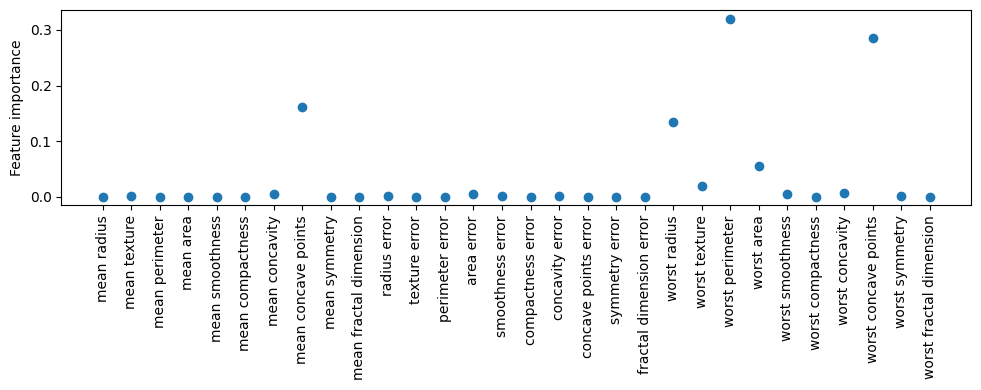

In [5]:
gbrt = GradientBoostingClassifier(random_state=0, max_depth=1)
gbrt.fit(X_train, y_train)

plt.figure(figsize=(10, 4))
plt.plot(gbrt.feature_importances_, "o")
plt.xticks(range(cancer.data.shape[1]), cancer.feature_names, rotation=90)
plt.ylabel("Feature importance")
plt.tight_layout()
plt.show()